# BÀI THỰC HÀNH AGENT 01: XÂY DỰNG TÁC TỬ HỌC TĂNG CƯỜNG (REINFORCEMENT LEARNING AGENT)
### Môn học: Phát triển các hệ thống thông minh (PTIT)
- **Sinh viên thực hiện**: Phạm Văn Tư
- **Mã sinh viên**: B23DCCN879
- **Lớp**: D23CTPM01 | **Nhóm môn học**: CT
- **Tài liệu tham chiếu**: GeeksforGeeks [4] - *What is Reinforcement Learning?* (Q-Learning Robot Maze Navigation)
---
Mục tiêu: Hiện thực hóa một Tác tử Tự trị (Autonomous RL Agent) sử dụng thuật toán Q-Learning để tự học cách tìm đường đi tối ưu qua mê cung kích thước 10x10 có chướng ngại vật từ vị trí xuất phát  đến đích  mà không cần con người nạp trước bản đồ đường đi.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# 1. KHỞI TẠO MÔI TRƯỜNG MÊ CUNG (10x10 MAZE ENVIRONMENT)
# 0: Đường đi hợp lệ, 1: Chướng ngại vật / Tường lửa (Fire/Obstacle)
maze = np.array([
    [0, 1, 1, 1, 1, 1, 1, 1, 1, 1],
    [0, 0, 0, 0, 1, 0, 0, 0, 0, 1],
    [1, 1, 1, 0, 1, 0, 1, 1, 0, 1],
    [1, 0, 0, 0, 0, 0, 1, 0, 0, 1],
    [1, 0, 1, 1, 1, 1, 1, 0, 1, 1],
    [1, 0, 1, 0, 0, 0, 0, 0, 1, 1],
    [1, 0, 1, 0, 1, 1, 1, 0, 1, 1],
    [1, 0, 1, 0, 1, 0, 0, 0, 1, 1],
    [1, 0, 1, 0, 1, 0, 1, 0, 0, 1],
    [1, 1, 1, 0, 1, 1, 1, 1, 0, 0]
])

start = (0, 0)
goal = (9, 9)

# 2. CẤU HÌNH THAM SỐ HỌC TĂNG CƯỜNG (RL HYPERPARAMETERS - GEEKSFORGEEKS [4])
num_episodes = 5000
alpha = 0.1       # Tốc độ học (Learning Rate)
gamma = 0.9       # Hệ số chiết khấu phần thưởng tương lai (Discount Factor)
epsilon = 0.5     # Tỷ lệ thăm dò ban đầu (Exploration Rate)

reward_fire = -10 # Phạt khi va vào chướng ngại vật
reward_goal = 50  # Thưởng lớn khi về đích thành công
reward_step = -1  # Phạt nhẹ mỗi bước đi để tối ưu hóa thời gian

# 4 hành động khả dĩ: Trái, Phải, Lên, Xuống
actions = [(0, -1), (0, 1), (-1, 0), (1, 0)]
action_names = ["Trái", "Phải", "Lên", "Xuống"]

# Khởi tạo Bảng giá trị Q-Table với kích thước (10, 10, 4)
Q = np.zeros(maze.shape + (len(actions),))
print(f"✓ Khởi tạo môi trường Mê cung: {maze.shape[0]}x{maze.shape[1]}")
print(f"✓ Kích thước Q-Table: {Q.shape} | Số tập huấn luyện (Episodes): {num_episodes}")

✓ Khởi tạo môi trường Mê cung: 10x10
✓ Kích thước Q-Table: (10, 10, 4) | Số tập huấn luyện (Episodes): 5000


In [2]:
# 3. ĐỊNH NGHĨA QUY TẮC VẬN HÀNH & CƠ CHẾ SUY LUẬN TỰ TRỊ
def is_valid(pos):
    r, c = pos
    if r < 0 or r >= maze.shape[0]:
        return False
    if c < 0 or c >= maze.shape[1]:
        return False
    return maze[r, c] == 0

def choose_action(state, current_eps):
    # Chiến lược Epsilon-Greedy cân bằng Thăm dò (Exploration) và Khai thác (Exploitation)
    if np.random.random() < current_eps:
        return np.random.randint(len(actions))
    else:
        return np.argmax(Q[state])

# 4. VÒNG LẶP HUẤN LUYỆN TÁC TỬ (Q-LEARNING TRAINING LOOP)
rewards_all_episodes = []
curr_eps = epsilon

for episode in range(num_episodes):
    state = start
    total_rewards = 0
    done = False
    step_count = 0

    while not done and step_count < 200:
        step_count += 1
        action_index = choose_action(state, curr_eps)
        action = actions[action_index]

        next_state = (state[0] + action[0], state[1] + action[1])

        if not is_valid(next_state):
            reward = reward_fire
            done = True
            next_max = 0
        elif next_state == goal:
            reward = reward_goal
            done = True
            next_max = 0
        else:
            reward = reward_step
            next_max = np.max(Q[next_state])

        # Cập nhật giá trị Q theo Phương trình Bellman
        old_value = Q[state][action_index]
        Q[state][action_index] = old_value + alpha * (
            reward + gamma * next_max - old_value
        )

        if is_valid(next_state):
            state = next_state

        total_rewards += reward

    # Giảm dần epsilon để chuyển dần từ khám phá sang áp dụng tri thức đã học
    curr_eps = max(0.01, curr_eps * 0.995)
    rewards_all_episodes.append(total_rewards)

    if (episode + 1) % 1000 == 0 or (episode + 1) == 1:
        avg_r = np.mean(rewards_all_episodes[-min(1000, episode + 1):])
        print(f"  [Tập {episode+1:5d}/{num_episodes}] Reward TB: {avg_r:7.2f} | Epsilon: {curr_eps:.4f}")

print(f"✓ Hoàn tất huấn luyện 5000 Episodes!")
print(f"  - Epsilon cuối cùng: {curr_eps:.4f} (99% quyết định dựa trên tri thức Q-Table)")
print(f"  - Phần thưởng trung bình 100 tập cuối: {np.mean(rewards_all_episodes[-100:]):.2f}")

  [Tập     1/5000] Reward TB:  -10.00 | Epsilon: 0.4975
  [Tập  1000/5000] Reward TB:  -12.00 | Epsilon: 0.0100
  [Tập  2000/5000] Reward TB:   22.11 | Epsilon: 0.0100


  [Tập  3000/5000] Reward TB:   20.88 | Epsilon: 0.0100
  [Tập  4000/5000] Reward TB:   20.92 | Epsilon: 0.0100
  [Tập  5000/5000] Reward TB:   22.30 | Epsilon: 0.0100
✓ Hoàn tất huấn luyện 5000 Episodes!
  - Epsilon cuối cùng: 0.0100 (99% quyết định dựa trên tri thức Q-Table)
  - Phần thưởng trung bình 100 tập cuối: 21.30


✓ Tìm thấy lộ trình tối ưu qua mê cung: 25 bước!
  Tọa độ hành trình: [(0, 0), (1, 0), (1, 1), (1, 2), (1, 3), (2, 3), (3, 3), (3, 4), (3, 5), (2, 5), (1, 5), (1, 6), (1, 7), (1, 8), (2, 8), (3, 8), (3, 7), (4, 7), (5, 7), (6, 7), (7, 7), (8, 7), (8, 8), (9, 8), (9, 9)]
  Đến đích thành công (Goal Reached): True


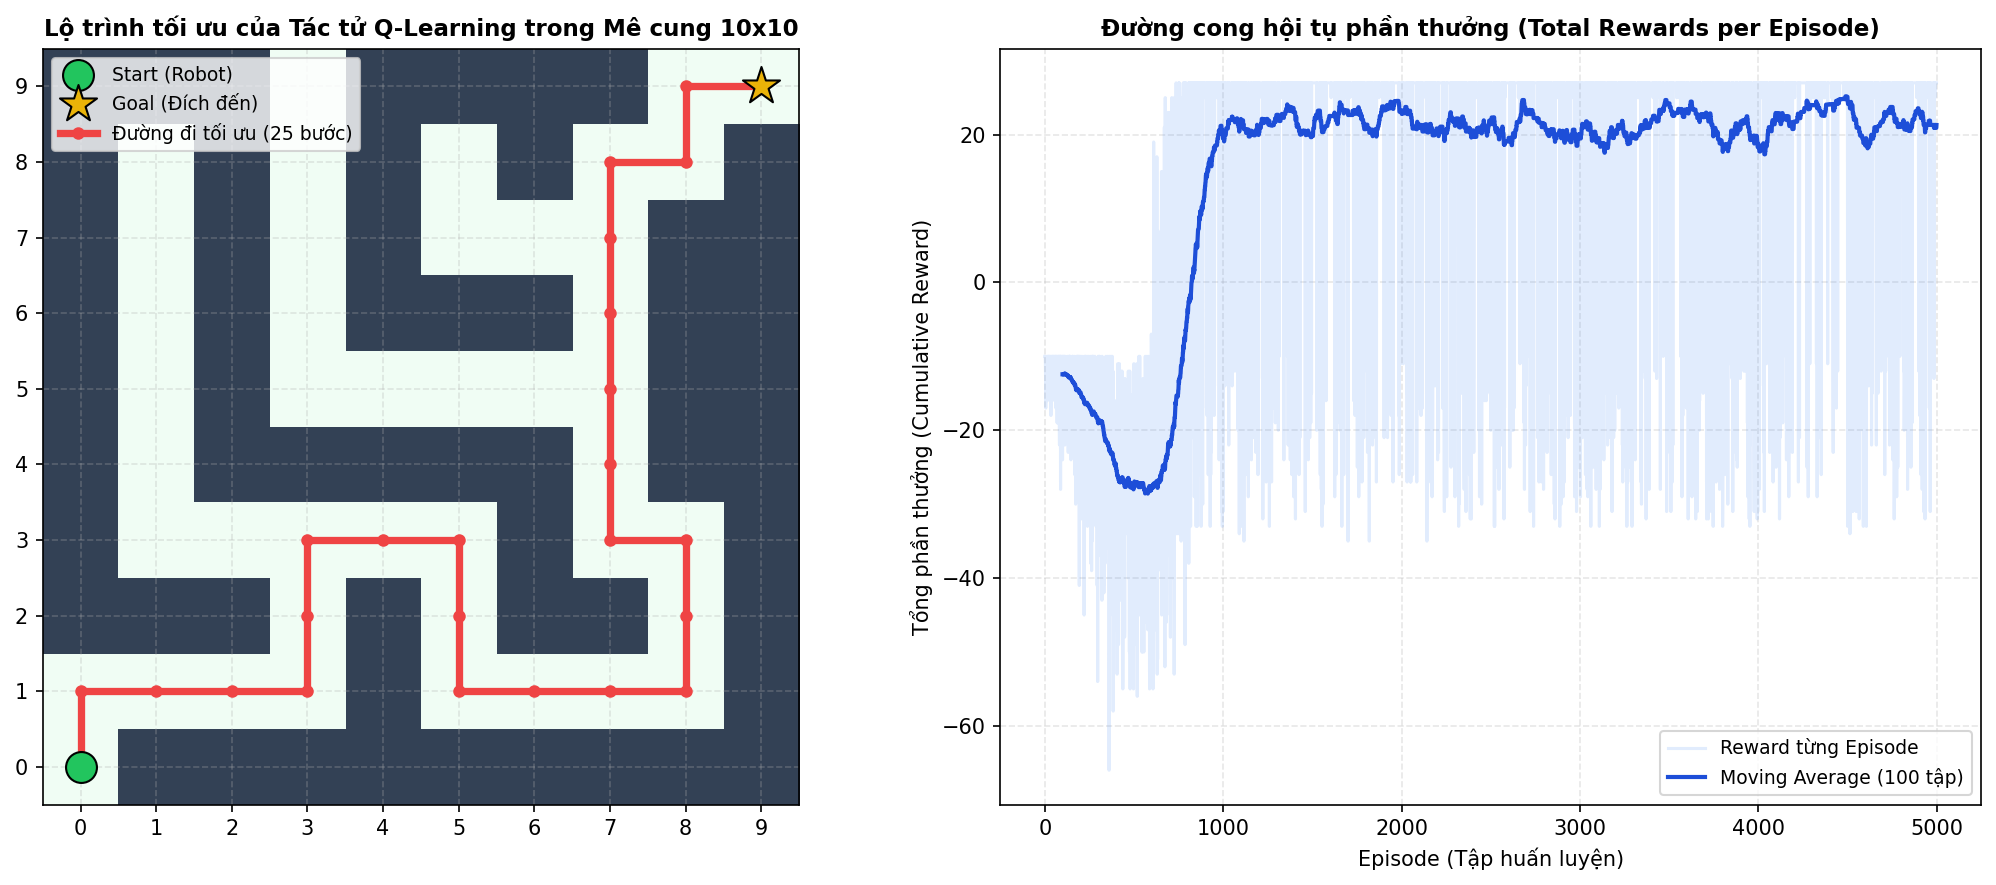

✓ Đã lưu biểu đồ kết quả: fig_rl_maze_and_rewards.png


In [3]:
# 5. TRUY XUẤT ĐƯỜNG ĐI TỐI ƯU CỦA TÁC TỬ (OPTIMAL POLICY EXTRACTION)
def get_optimal_path(Q, start, goal, actions, maze, max_steps=200):
    path = [start]
    state = start
    visited = set()

    for _ in range(max_steps):
        if state == goal:
            break
        visited.add(state)

        best_action = None
        best_value = -float("inf")

        for idx, move in enumerate(actions):
            next_state = (state[0] + move[0], state[1] + move[1])
            if (0 <= next_state[0] < maze.shape[0] and
                0 <= next_state[1] < maze.shape[1] and
                maze[next_state] == 0 and
                next_state not in visited):
                if Q[state][idx] > best_value:
                    best_value = Q[state][idx]
                    best_action = idx

        if best_action is None:
            break

        move = actions[best_action]
        state = (state[0] + move[0], state[1] + move[1])
        path.append(state)

    return path

optimal_path = get_optimal_path(Q, start, goal, actions, maze)
print(f"✓ Tìm thấy lộ trình tối ưu qua mê cung: {len(optimal_path)} bước!")
print(f"  Tọa độ hành trình: {optimal_path}")
print(f"  Đến đích thành công (Goal Reached): {optimal_path[-1] == goal}")

# 6. TRỰC QUAN HÓA KẾT QUẢ ĐỒ THỊ VÀ LỘ TRÌNH
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), dpi=150)

# Biểu đồ 1: Bản đồ Mê cung và Đường đi của Robot
cmap = ListedColormap(["#f0fdf4", "#334155"])
ax1.imshow(maze, cmap=cmap)
ax1.scatter(start[1], start[0], marker="o", color="#22c55e", edgecolors="black", s=220, label="Start (Robot)", zorder=5)
ax1.scatter(goal[1], goal[0], marker="*", color="#eab308", edgecolors="black", s=350, label="Goal (Đích đến)", zorder=5)
rows, cols = zip(*optimal_path)
ax1.plot(cols, rows, color="#ef4444", linewidth=3.5, marker="o", markersize=5, label="Đường đi tối ưu (25 bước)", zorder=4)
ax1.set_title("Lộ trình tối ưu của Tác tử Q-Learning trong Mê cung 10x10", fontsize=11, fontweight="bold")
ax1.invert_yaxis()
ax1.set_xticks(range(maze.shape[1]))
ax1.set_yticks(range(maze.shape[0]))
ax1.grid(True, alpha=0.3, linestyle="--")
ax1.legend(loc="upper left", fontsize=9)

# Biểu đồ 2: Đường cong hội tụ phần thưởng qua các Episode
# Làm mượt đường cong bằng Moving Average
window = 100
smoothed_rewards = np.convolve(rewards_all_episodes, np.ones(window)/window, mode="valid")
ax2.plot(rewards_all_episodes, alpha=0.15, color="#3b82f6", label="Reward từng Episode")
ax2.plot(range(window-1, num_episodes), smoothed_rewards, color="#1d4ed8", linewidth=2, label=f"Moving Average ({window} tập)")
ax2.set_title("Đường cong hội tụ phần thưởng (Total Rewards per Episode)", fontsize=11, fontweight="bold")
ax2.set_xlabel("Episode (Tập huấn luyện)", fontsize=10)
ax2.set_ylabel("Tổng phần thưởng (Cumulative Reward)", fontsize=10)
ax2.grid(True, alpha=0.3, linestyle="--")
ax2.legend(loc="lower right", fontsize=9)

plt.tight_layout()
img_out = os.path.abspath("../images/fig_rl_maze_and_rewards.png") if os.path.exists("../images") else "Report/agent01_CT_02_tupv/images/fig_rl_maze_and_rewards.png"
os.makedirs(os.path.dirname(img_out), exist_ok=True)
plt.savefig(img_out, dpi=300)
plt.show()
print("✓ Đã lưu biểu đồ kết quả: fig_rl_maze_and_rewards.png")